In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIII_raw.mtx').T

In [3]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIII_raw_cellnames.csv")["x"]

In [4]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIII_raw_genenames.csv")["x"]

In [5]:
adata.obs_names = cellnames
adata.var_names = genenames

In [6]:
family_info = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/stemdata_stageIII_metatable.csv')

In [7]:
family_info = family_info.set_index("Unnamed: 0")
family_info

,Sample,Cell.Barcode,Virus.Barcode,Cluster.Id
Unnamed: 0,,,,
AAACCCACAAATTAGG-1_1,Stage_III_Exp2,AAACCCACAAATTAGG-1_1,GTGAGAGACAGTCTGTCAGTGTGTCTGTGTGA-1-2,III-NPaHB
AAACCCACAGGTCAAG-1_1,Stage_III_Exp2,AAACCCACAGGTCAAG-1_1,GAGACTGTCTCTGACACTGTCTGTCAGTGACT-1-2,III-NPaHB
AAACCCACATTCTTCA-1_1,Stage_III_Exp2,AAACCCACATTCTTCA-1_1,NaN,NaN
AAACCCAGTTTGATCG-1_1,Stage_III_Exp2,AAACCCAGTTTGATCG-1_1,NaN,NaN
AAACCCATCGCATTGA-1_1,Stage_III_Exp2,AAACCCATCGCATTGA-1_1,NaN,NaN
...,...,...,...,...
TTTGGTTGTACAAGCG-1_8,Stage_III_Rep3_2_Exp3,TTTGGTTGTACAAGCG-1_8,NaN,NaN
TTTGGTTGTCCGGATC-1_8,Stage_III_Rep3_2_Exp3,TTTGGTTGTCCGGATC-1_8,NaN,NaN
TTTGGTTGTGGAAATT-1_8,Stage_III_Rep3_2_Exp3,TTTGGTTGTGGAAATT-1_8,NaN,NaN


In [8]:
adata.obs["barcode"] = adata.obs_names.map(family_info["Virus.Barcode"])

In [9]:
adata.obs["barcode"]

x
AAACCCACAAATTAGG-1_1    GTGAGAGACAGTCTGTCAGTGTGTCTGTGTGA-1-2
AAACCCACAGGTCAAG-1_1    GAGACTGTCTCTGACACTGTCTGTCAGTGACT-1-2
AAACCCACATTCTTCA-1_1                                     NaN
AAACCCAGTTTGATCG-1_1                                     NaN
AAACCCATCGCATTGA-1_1                                     NaN
                                        ...                 
TTTGGTTGTACAAGCG-1_8                                     NaN
TTTGGTTGTCCGGATC-1_8                                     NaN
TTTGGTTGTGGAAATT-1_8                                     NaN
TTTGTTGCATGTACGT-1_8                                     NaN
TTTGTTGGTACAGAAT-1_8                                     NaN
Name: barcode, Length: 54061, dtype: object

In [10]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [11]:
adata_no_nan

View of AnnData object with n_obs × n_vars = 24158 × 27044
    obs: 'barcode'

In [12]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

/tmp/ipykernel_2586555/2707677046.py:4: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")


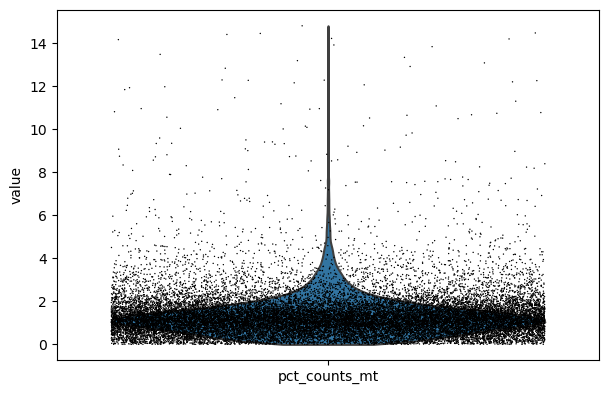

In [13]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [14]:
# Filter cells with >5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 5].copy()

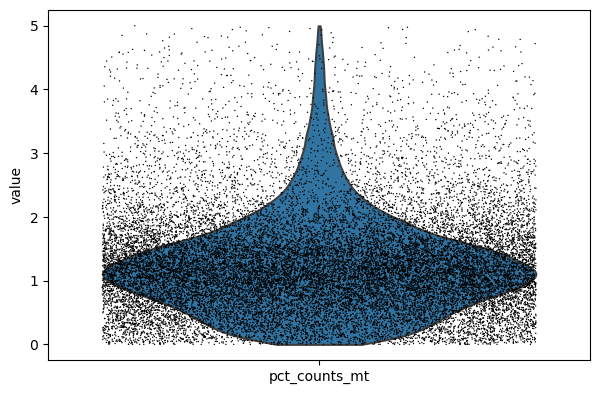

In [15]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [16]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [17]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [18]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [19]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [20]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [21]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [22]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [23]:
df

x,RP11-34P13.3,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP5-857K21.4,RP11-206L10.9,FAM87B,LINC00115,FAM41C,...,IL17REL,AF241725.6,AP000146.2,KRTAP19-7,DSCR8,AL773572.7,KRTAP10-2,AP001471.1,barcode,barcode_cont
0,0.0,0.0,0.500075,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGAGAGACAGTCTGTCAGTGTGTCTGTGTGA-1-2,0
1,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.487536,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GAGACTGTCTCTGACACTGTCTGTCAGTGACT-1-2,1
2,0.0,0.0,0.327573,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTCTCACAGTCACTCTGTGTGTCAGTGAC-1-2;GTGTGTCTGA...,2
3,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTCAGACTGTGTGTGTCTGTCTCTGTCTGT-1-2,3
4,0.0,0.0,1.028643,0.541689,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTGAGTGTCTCTGTGAGTGTCTGTGTGTGT-1-2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23878,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTGTGACTGAGTGACTCTGTCTGTGTGTCT-3-3;CTGTCAGTG...,15787
23879,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGAGTGTCTCAGTGTGTCTCTGTGTGTGTGT-3-3,15788
23880,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTCACTCAGTGTCTGTGTGACACTCTGTGT-3-3;CTCTCACTC...,15789
23881,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTCTCTGAGTGACTGTCTCTCTCAGTGTCT-3-3;GTGTGTGTG...,15790


In [24]:
df = df.drop("barcode", axis=1)

In [25]:
df.to_pickle('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl')
